# 🍁 Canadian Credit Risk Model — Analysis

Predict loan-default probability for the Canadian banking context (**CAD**, province, **Equifax/TransUnion 300–900 credit score**), calibrate it, explain it with SHAP, and audit it for fairness under the **Canadian Human Rights Act** — aligned to **OSFI Guideline E-23**.

*Data is a public credit-risk dataset adapted to a Canadian framing (see `data/canadianize.py`); a demonstration proxy, not real Canadian bank data (PIPEDA).*

In [ ]:
import pandas as pd, loan_default as L
df = L.engineer_features(L.load_data())
df[['credit_score','person_income','loan_amnt','loan_int_rate']].describe().round(1)

       credit_score  person_income  loan_amnt  loan_int_rate
count       24435.0        24435.0    24435.0        24435.0
mean          728.2        66156.1     9583.8           11.0
std           108.7        65688.5     6330.1            3.1
min           300.0         4000.0      500.0            5.4
25%           665.0        38400.0     5000.0            8.5
50%           758.0        55000.0     8000.0           11.0
75%           810.0        79200.0    12100.0           13.1
max           900.0      6000000.0    35000.0           22.5

### Province mix (sampled from StatsCan population shares)

In [ ]:
df['province'].value_counts(normalize=True).round(3)

province
ON    0.388
QC    0.226
BC    0.138
AB    0.119
MB    0.034
SK    0.029
NS    0.027
NB    0.021
NL    0.013
PE    0.005

## 1. The target is imbalanced

About 1 in 5 loans defaults, so recall and calibration matter more than raw accuracy.

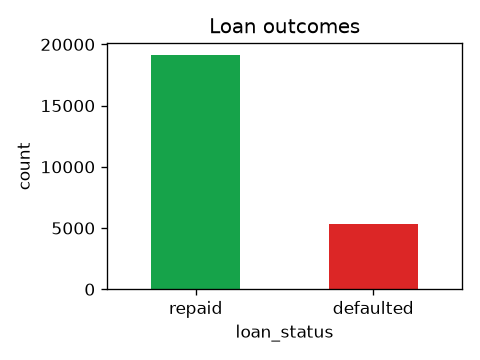

In [ ]:
df['loan_status'].value_counts().plot.bar()

## 2. Held-out performance (calibrated Random Forest)

Metrics on the 20% test set, including **Brier** and **ECE** which measure how well-calibrated the probabilities are (lower = better).

In [ ]:
import json; json.load(open('model_meta.json'))['metrics']

accuracy    0.9304
precision   0.9568
recall      0.711
f1          0.8158
roc_auc     0.9287
brier       0.059
ece         0.0055

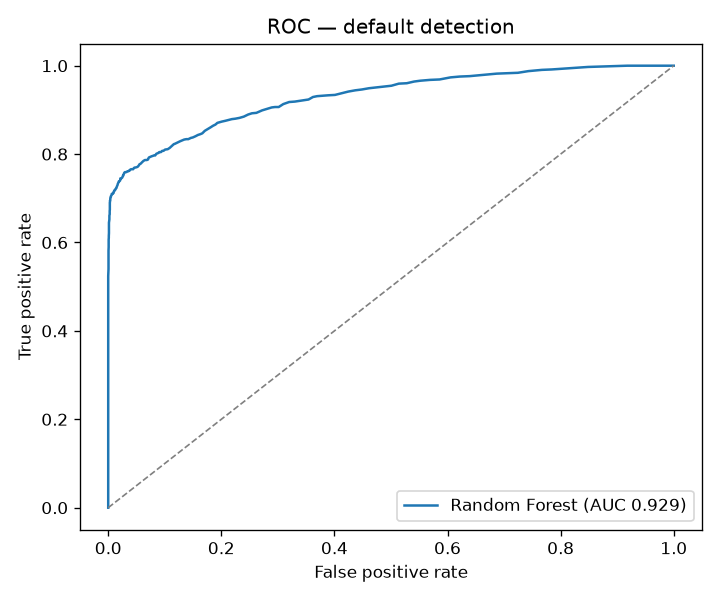

In [ ]:
# ROC on the held-out set
plot_roc(...)

## 3. Calibration — are the probabilities trustworthy?

OSFI E-23 expects sound outputs; a PD feeds IFRS 9 provisioning. The reliability curve shows calibrated predictions track the diagonal.

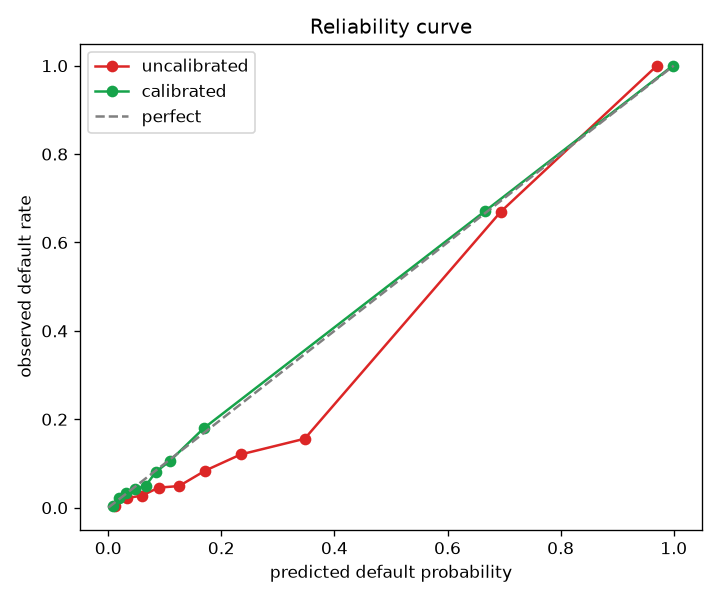

In [ ]:
from calibration import main as calibrate  # Brier/ECE + reliability curve

## 4. Explainability (SHAP)

Which features drive the score — globally, and per applicant for adverse-action reasons. Credit score dominates, as expected.

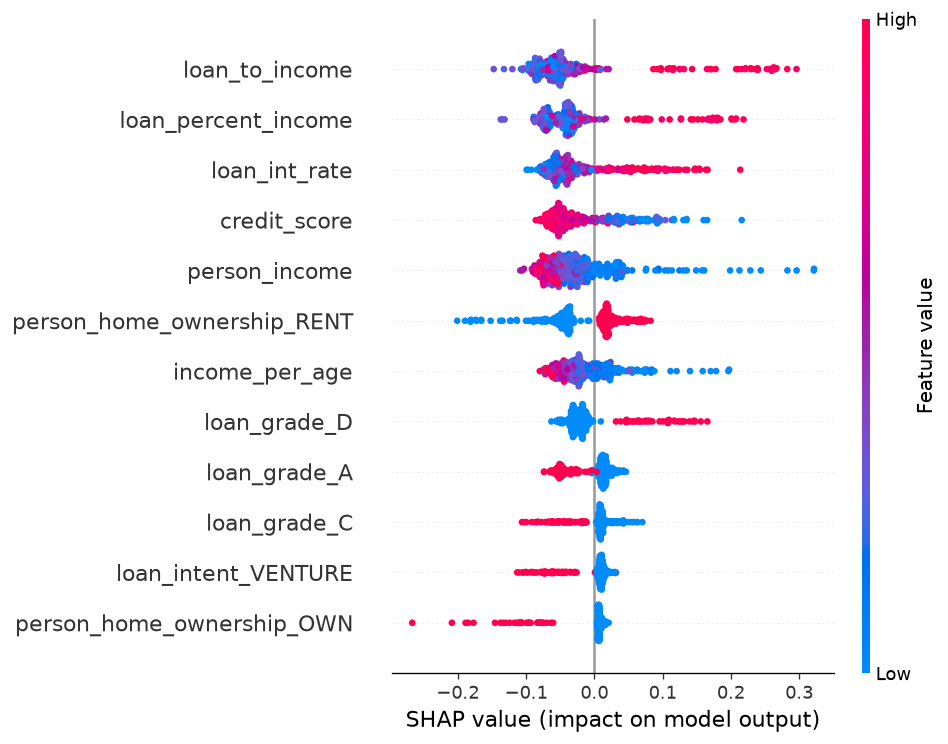

In [ ]:
from explain import save_global_summary

## 5. Cost-based decision threshold

Approving a defaulter loses `principal × LGD`; declining a good borrower loses foregone interest. Because the model is calibrated, the cost-optimal cutoff sits near 0.49.

In [ ]:
from threshold import optimal_threshold
optimal_threshold(scored['actual'], scored['proba'], scored['loan_amnt'], scored['loan_int_rate'])

optimal threshold : 0.49
expected cost     : $1,826,399 CAD
cost at 0.50      : $1,841,424 CAD
saved vs 0.50     : $15,025 CAD

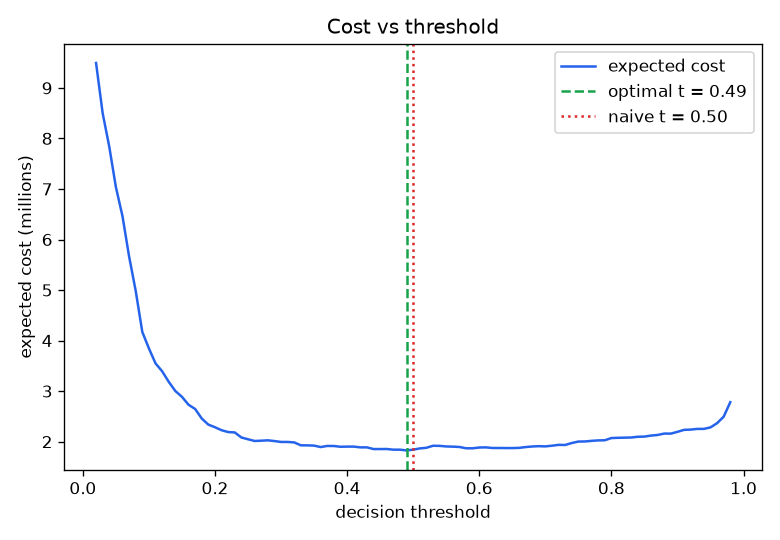

In [ ]:
plot_cost_curve(...)

## 6. Fairness audit (Fairlearn · Canadian Human Rights Act)

Approval parity across **age** (protected ground) and **province**. Both pass the four-fifths rule. No sex/gender field in the data, so that ground is not audited.

In [ ]:
from fairness import group_metrics
group_metrics(scored, 'age_band', t)

age_band      n  approval_rate  default_rate  recall   fpr  approval_ratio 80%_rule
   26-40 2390.0          0.855         0.204   0.672 0.010           0.980       ok
   41-60  203.0          0.872         0.167   0.765 0.000           1.000       ok
     60+    7.0          0.857         0.000   0.000 0.143           0.983       ok
    <=25 2287.0          0.817         0.235   0.749 0.010           0.937       ok

In [ ]:
group_metrics(scored, 'province', t)

province      n  approval_rate  default_rate  recall   fpr  approval_ratio 80%_rule
      AB  556.0          0.847         0.200   0.730 0.009           0.953       ok
      BC  670.0          0.813         0.249   0.725 0.008           0.915       ok
      MB  176.0          0.852         0.210   0.703 0.000           0.959       ok
      NB   94.0          0.755         0.309   0.759 0.015           0.850       ok
      NL   54.0          0.889         0.167   0.667 0.000           1.000       ok
      NS  123.0          0.886         0.138   0.824 0.000           0.997       ok
      ON 1955.0          0.838         0.213   0.707 0.015           0.943       ok
      PE   21.0          0.810         0.286   0.667 0.000           0.911       ok
      QC 1103.0          0.845         0.212   0.709 0.006           0.951       ok
      SK  135.0          0.837         0.244   0.667 0.000           0.942       ok

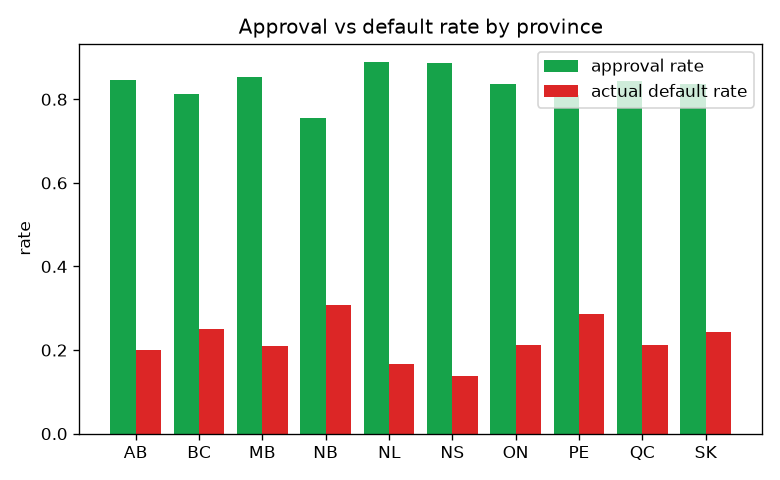

In [ ]:
plot_group_metrics(group_metrics(scored,'province',t), 'province', 'reports/fairness_province.png')

---
**Takeaway.** A calibrated Random Forest reaches ROC AUC ~0.93 with near-zero calibration error, is explainable per decision via SHAP, and passes a Fairlearn fairness screen on age and province — the kind of model-risk evidence OSFI Guideline E-23 expects from a Canadian credit model.